In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

accounts = pd.read_csv("../data/clean/accounts_clean.csv")

accounts["open_date"] = pd.to_datetime(accounts["open_date"])

In [7]:
accounts.isnull().sum()
accounts.duplicated().sum()

np.int64(0)

,account_count
account_type,
Savings,38198
Checking,21309
Credit Card,12840
Fixed Deposit,8590
Loan Account,4063


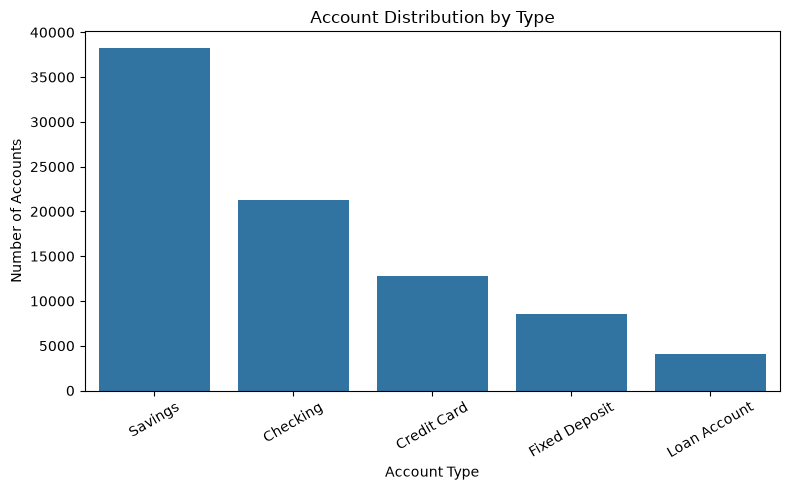

In [8]:
account_type_counts = accounts["account_type"].value_counts()

display(account_type_counts.to_frame("account_count"))

plt.figure(figsize=(8, 5))
sns.countplot(data=accounts, x="account_type", order=account_type_counts.index)
plt.title("Account Distribution by Type")
plt.xlabel("Account Type")
plt.ylabel("Number of Accounts")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Dominant Core Product: Savings accounts represent the majority of customer relationships (~38,000 accounts), followed by Checking (~21,000 accounts).   

Secondary Financial Products: Credit Cards (~13,000) show moderate adoption, while specialized investment/lending products—Fixed Deposit (~8,500) and Loan Account (~4,000)—have the lowest volume.  

 Main Takeaways:
 Primary Onboarding Channel: Savings accounts serve as the primary entry point for customers joining the institution.   
 Cross-Selling Opportunity: Focus on cross-selling higher-margin products (Credit Cards, Fixed Deposits, and Loans) to existing Savings and Checking account holders to increase revenue per customer. 

,account_count
account_status,
Active,69879
Dormant,10053
Closed,5068


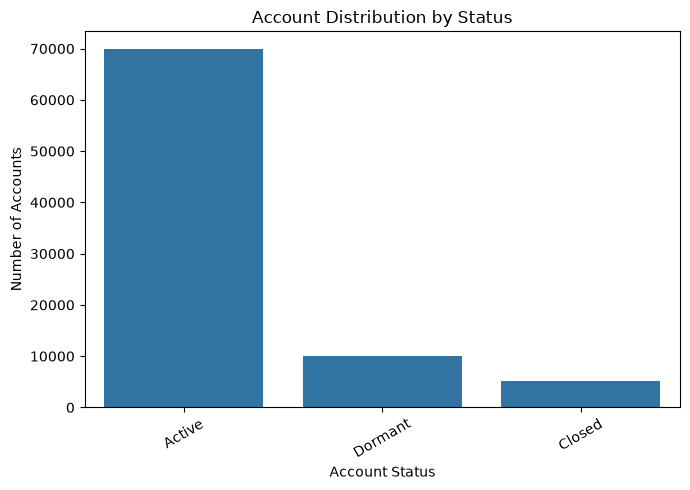

In [9]:
status_counts = accounts["account_status"].value_counts()

display(status_counts.to_frame("account_count"))

plt.figure(figsize=(7, 5))
sns.countplot(data=accounts, x="account_status", order=status_counts.index)
plt.title("Account Distribution by Status")
plt.xlabel("Account Status")
plt.ylabel("Number of Accounts")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

High Customer Engagement: Overwhelmingly, most accounts are Active (~70,000), showing strong overall engagement and portfolio health.

Re-engagement Opportunity: A notable segment of accounts is Dormant (~10,000). Targeted activation campaigns (e.g., promotional offers, feature reminders) can re-engage these users before they permanently churn.   

Low Churn Rate: Closed accounts are relatively low (~5,000), indicating minimal permanent attrition.   

Main Takeaway: Focus retention marketing efforts on winning back the Dormant customer pool to prevent them from transitioning to Closed status.   

count     85000.00
mean      28337.45
std       54173.07
min     -199901.67
25%        4256.40
50%       22647.56
75%       47765.98
max      249954.11
Name: balance, dtype: float64


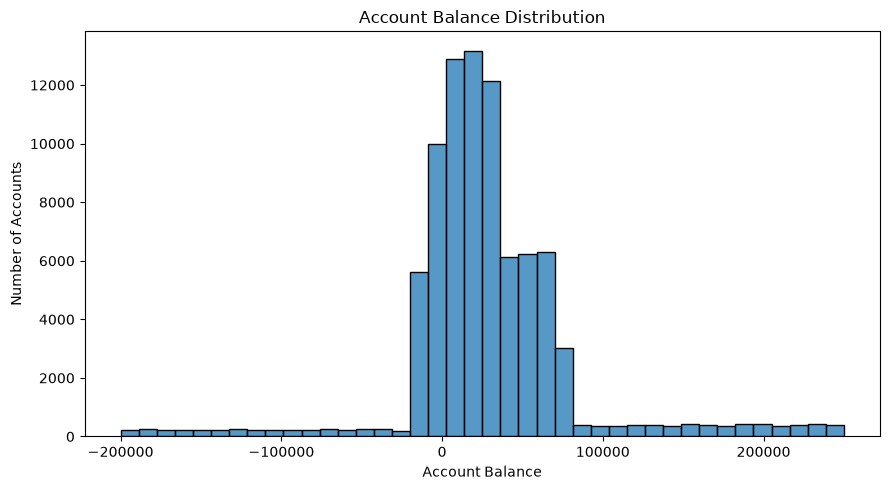

In [10]:
print(accounts["balance"].describe().round(2))

plt.figure(figsize=(9, 5))
sns.histplot(data=accounts, x="balance", bins=40)
plt.title("Account Balance Distribution")
plt.xlabel("Account Balance")
plt.ylabel("Number of Accounts")
plt.tight_layout()
plt.show()

Concentration at Low Positive Balances: Most accounts are heavily concentrated around $0 to $50,000, with peak volume right around $10,000–$30,000.   
Extreme Tail Balances: There is a wide spread of accounts with balances extending up to +$250,000 (high-net-worth accounts) and down to -$200,000 (overdrawn/loan accounts).   
Significant Overdraft / Debt Exposure: A notable proportion of accounts carry negative balances (down to -$200,000), representing active credit lines, overdrafts, or potential default risk.   
Main Takeaways:
Credit Risk Management: Closely monitor and manage accounts in the negative range (-$50,000 to -$200,000) to mitigate credit default risk.   

Wealth Management Upsell: Target the upper tail ($100,000+) with wealth management products, fixed deposits, or premium investment services to retain high-value deposits.

In [11]:
account_type_summary = accounts.groupby("account_type").agg(
    account_count=("account_id", "count"),
    average_balance=("balance", "mean"),
    median_balance=("balance", "median"),
    total_balance=("balance", "sum")
).round(2)

display(account_type_summary.sort_values("total_balance", ascending=False))

,account_count,average_balance,median_balance,total_balance
account_type,,,,
Savings,38198,38039.45,38134.06,1.453031e+09
Fixed Deposit,8590,126419.12,126423.24,1.085940e+09
Checking,21309,17581.97,17679.41,3.746542e+08
Credit Card,12840,-7513.26,-7548.56,-9.647022e+07
Loan Account,4063,-100534.65,-100778.25,-4.084723e+08


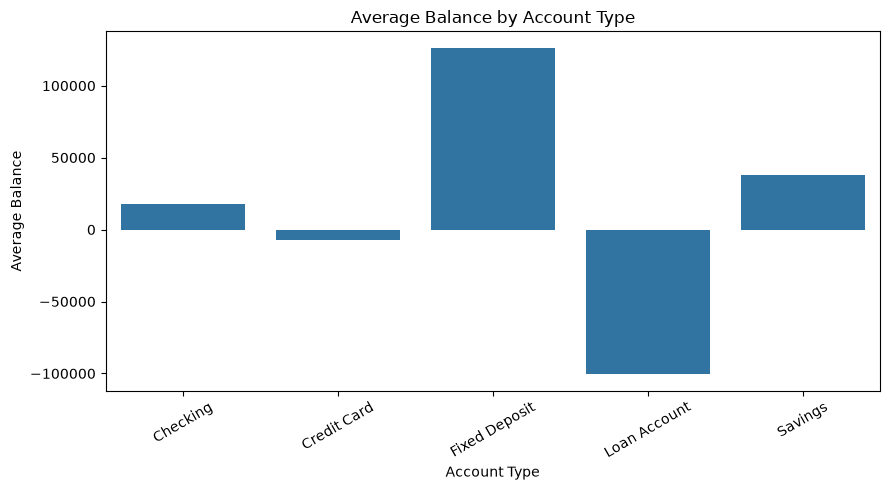

In [12]:
balance_by_type = account_type_summary.reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(
    data=balance_by_type,
    x="account_type",
    y="average_balance"
)
plt.title("Average Balance by Account Type")
plt.xlabel("Account Type")
plt.ylabel("Average Balance")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Highest Liquidity & Reserves: Fixed Deposit accounts hold by far the highest average positive balance (~$125,000), representing long-term savings and term investments.   

Core Deposit Accounts: Savings accounts maintain a moderate positive average balance (~$38,000), followed by Checking accounts (~$18,000) for daily transactional liquidity.   

Liabilities & Outstanding Debt: Loan Accounts carry a significant negative average balance (~-$100,000), representing active principal debts, while Credit Cards show a minor negative average balance (~-$7,000) reflecting revolving monthly credit.   

Main Takeaways:
Deposit Growth: Leverage high-value Fixed Deposit customers for premium wealth management or cross-selling investment products.   

Loan Portfolio Monitoring: Ensure adequate risk management and payment collection strategies for Loan Accounts due to their high negative exposure. 

In [15]:
branch_accounts = accounts.groupby("branch_id").agg(
    total_accounts=("account_id", "count"),
    average_balance=("balance", "mean"),
    total_balance=("balance", "sum")
)

branch_accounts["average_balance"] = branch_accounts["average_balance"].round(2)
branch_accounts["total_balance"] = branch_accounts["total_balance"].round(2)

display(branch_accounts.head(10).map(
    lambda x: f"{x:,.2f}" if isinstance(x, (int, float)) else x
))

,total_accounts,average_balance,total_balance
branch_id,,,
B001,"3,429.00","26,605.82","91,231,349.05"
B002,"3,426.00","29,536.15","101,190,855.14"
B003,"3,374.00","28,807.44","97,196,304.99"
B004,"3,365.00","27,719.61","93,276,472.16"
B005,"3,424.00","29,439.82","100,801,930.49"
B006,"3,422.00","28,487.26","97,483,416.47"
B007,"3,313.00","28,809.00","95,444,216.19"
B008,"3,443.00","29,025.04","99,933,221.52"
B009,"3,446.00","27,234.71","93,850,809.27"
